# 01 - Actual AIS measurement audit

This notebook uses **real, already-acquired NOAA 2024 cargo-vessel proxy observations**. It does not download data or mutate geofences, measurements, thresholds or the forecast study. Source coverage is not vessel-detection coverage. The receipt below determines whether the displayed aggregate scope is pilot, partial year or full year.

The package reconstruction is illustrated on one bounded source day; that example is explicitly censored at its edges. No MMSI or vessel name is displayed. Historical geometry and cargo broadcast codes do not establish containership identity or verified congestion.

In [1]:
from pathlib import Path
import json, hashlib
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
def read_json(relative):
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))
def sha(relative):
    return hashlib.sha256((ROOT / relative).read_bytes()).hexdigest()
from scsi.geo.pipeline import read_cargo
from scsi.geo.cleaning import clean_points
from scsi.geo.geofences import classify_zones
from scsi.geo.episodes import reconstruct
from scsi.geo.coverage import daily_features
measurement = read_json("artifacts/audit/geo_measurement_receipt.json")
freeze = read_json("artifacts/audit/geo_pilot_freeze.json")
assert sha("data/geography/geofences_v1.geojson") == freeze["geometry_sha256"]
assert sha("artifacts/audit/geo_daily_features.csv") == measurement["daily_sha256"]
display(pd.DataFrame([{k: measurement[k] for k in ("status", "source_days", "expected_days", "measurement_start", "measurement_end", "cargo_proxy_points", "audit_rows", "classification")}]))
if measurement["source_days"] == 366:
    accepted = read_json("artifacts/audit/geo_finalization_state.json")
    assert accepted["status"] == "completed" and measurement["finalization_status"] == "completed"
    assert accepted["measurement_receipt_sha256"] == sha("artifacts/audit/geo_measurement_receipt.json")
    assert accepted["daily_sha256"] == measurement["daily_sha256"]
    for relative, expected in measurement["executed_code_sha256"].items():
        assert sha(relative) == expected
    acceptance_paths = {
        "corrected_legacy_full_year": "artifacts/audit/geo_postfreeze_correction_receipt.json",
        "current_implementation_no_legacy_rebuild": "artifacts/audit/geo_build_acceptance_receipt.json",
    }
    mode = measurement["acceptance_mode"]
    assert mode in acceptance_paths and accepted["acceptance_mode"] == mode
    acceptance_path = acceptance_paths[mode]
    acceptance_sha256 = sha(acceptance_path)
    for receipt in (measurement, accepted):
        assert receipt["acceptance_receipt_path"] == acceptance_path
        assert receipt["acceptance_receipt_sha256"] == acceptance_sha256
    if mode == "corrected_legacy_full_year":
        assert measurement["postfreeze_correction_receipt_sha256"] == acceptance_sha256
        assert accepted["correction_receipt_sha256"] == acceptance_sha256
    else:
        evidence = read_json(acceptance_path)
        assert evidence["acceptance_mode"] == mode
        assert evidence["legacy_outputs_rebuilt"] is False
        assert evidence["daily_sha256"] == measurement["daily_sha256"]
        assert evidence["executed_code_sha256"] == measurement["executed_code_sha256"]
    print("Acceptance mode:", mode)
    print("Accepted full-year measurement; 366 source partitions are not 100% vessel detection.")
else:
    print("Pilot/partial counts must not be described as a completed 366-day study.")


,status,source_days,expected_days,measurement_start,measurement_end,cargo_proxy_points,audit_rows,classification
0,full_year_measured,366,366,2024-01-01,2024-12-31,12408103,60,cargo-vessel proxy


Acceptance mode: current_implementation_no_legacy_rebuild
Accepted full-year measurement; 366 source partitions are not 100% vessel detection.


## Coverage-aware aggregate outputs

A source-complete day means its source partition was acquired, not that every vessel was received. Queue stocks can remain unknown even with a complete partition. Candidate vessel-hours are bounded observed intervals, not exhaustive delay. The past-only friction index requires at least 30 prior valid days and may therefore be unavailable in the pilot.

In [2]:
daily = pd.read_csv(ROOT / "artifacts/audit/geo_daily_features.csv")
coverage = daily.groupby("gateway_id").agg(calendar_rows=("date", "size"), source_complete_days=("source_complete", "sum"), queue_observed_days=("queue_stock", "count"), eligible_pings=("eligible_ping_count", "sum"), candidate_anchorage_hours=("anchorage_hours", "sum"), candidate_berth_hours=("berth_hours", "sum"), friction_available_days=("friction_index", "count"))
display(coverage)
display(daily.groupby(["gateway_id", "quality_flags"]).size().rename("gateway_days").reset_index())


,calendar_rows,source_complete_days,queue_observed_days,eligible_pings,candidate_anchorage_hours,candidate_berth_hours,friction_available_days
gateway_id,,,,,,,
new_york_new_jersey,366,366,352,4327034,10461.999444,92847.270278,322
san_pedro_bay,366,366,350,5712406,30825.891944,20853.348611,320
savannah,366,366,357,2368663,0.000000,38894.487222,327


,gateway_id,quality_flags,gateway_days
0,new_york_new_jersey,coverage_limited_lower_bounds;receiver_uptime_...,352
1,new_york_new_jersey,unreliable_day;coverage_limited_lower_bounds;r...,14
2,san_pedro_bay,coverage_limited_lower_bounds;receiver_uptime_...,350
3,san_pedro_bay,unreliable_day;coverage_limited_lower_bounds;r...,16
4,savannah,coverage_limited_lower_bounds;receiver_uptime_...,357
5,savannah,unreliable_day;coverage_limited_lower_bounds;r...,9


## One-day worked example using package functions

The sample day is the first day of the measured scope, selected without reference to an appealing queue pattern. Reconstructing a single day cannot recover all cross-midnight history: the full measured series remains the authority for aggregate results. Speed, persistence and maximum gap are the frozen settings.

In [3]:
sample_day = measurement["measurement_start"]
raw, partitions = read_cargo(ROOT, days={sample_day})
clean, cleaning_receipt = clean_points(raw)
del raw
geofences = read_json("data/geography/geofences_v1.geojson")
clean["zone"] = classify_zones(clean, geofences)
settings = freeze["geospatial"]
points, intervals, episodes = reconstruct(clean, settings["stationary_speed_knots"], settings["minimum_state_duration_minutes"], settings["maximum_interpolation_gap_minutes"])
example = daily_features(points, intervals, episodes, {sample_day}, sample_day, sample_day, settings["maximum_interpolation_gap_minutes"])
print("Bounded worked example only:", sample_day, "source partitions:", len(partitions))
display(pd.DataFrame([cleaning_receipt]))
display(points.groupby(["gateway_id", "state"]).size().rename("observed_points").reset_index())
display(example[["gateway_id", "date", "observed_arrivals", "anchorage_hours", "berth_hours", "queue_stock", "ping_continuity", "quality_flags"]])


Bounded worked example only: 2024-01-01 source partitions: 1


,raw_rows,valid_rows,invalid_essential,duplicate_rows,conflict_rows,impossible_jump_rows,unknown_speed_rows
0,16544,16544,0,0,0,0,0


,gateway_id,state,observed_points
0,new_york_new_jersey,ANCHORAGE_CANDIDATE,95
1,new_york_new_jersey,APPROACH,1692
2,new_york_new_jersey,BERTH_CANDIDATE,3033
3,new_york_new_jersey,PERSISTENCE_PENDING,87
4,new_york_new_jersey,TRANSIT,505
5,san_pedro_bay,ANCHORAGE_CANDIDATE,2044
6,san_pedro_bay,APPROACH,3277
7,san_pedro_bay,BERTH_CANDIDATE,543
8,san_pedro_bay,PERSISTENCE_PENDING,364
9,san_pedro_bay,TRANSIT,1561


,gateway_id,date,observed_arrivals,anchorage_hours,berth_hours,queue_stock,ping_continuity,quality_flags
0,san_pedro_bay,2024-01-01,4,102.203889,26.966667,3,1.000000,coverage_limited_lower_bounds;receiver_uptime_...
1,new_york_new_jersey,2024-01-01,0,4.481389,158.999167,0,0.999815,coverage_limited_lower_bounds;receiver_uptime_...
2,savannah,2024-01-01,0,0.000000,118.283611,0,1.000000,coverage_limited_lower_bounds;receiver_uptime_...


## Attributed geography and actual observed points

This image is a saved measurement output, not an illustrative rendering. Berth corridors and current-vintage boundaries remain approximations; observed cargo-proxy presence does not identify a stop reason. NOAA/MarineCadastre 2024 AIS; NOAA designated anchorages and NOAA ENC/Coast Pilot geometry evidence.

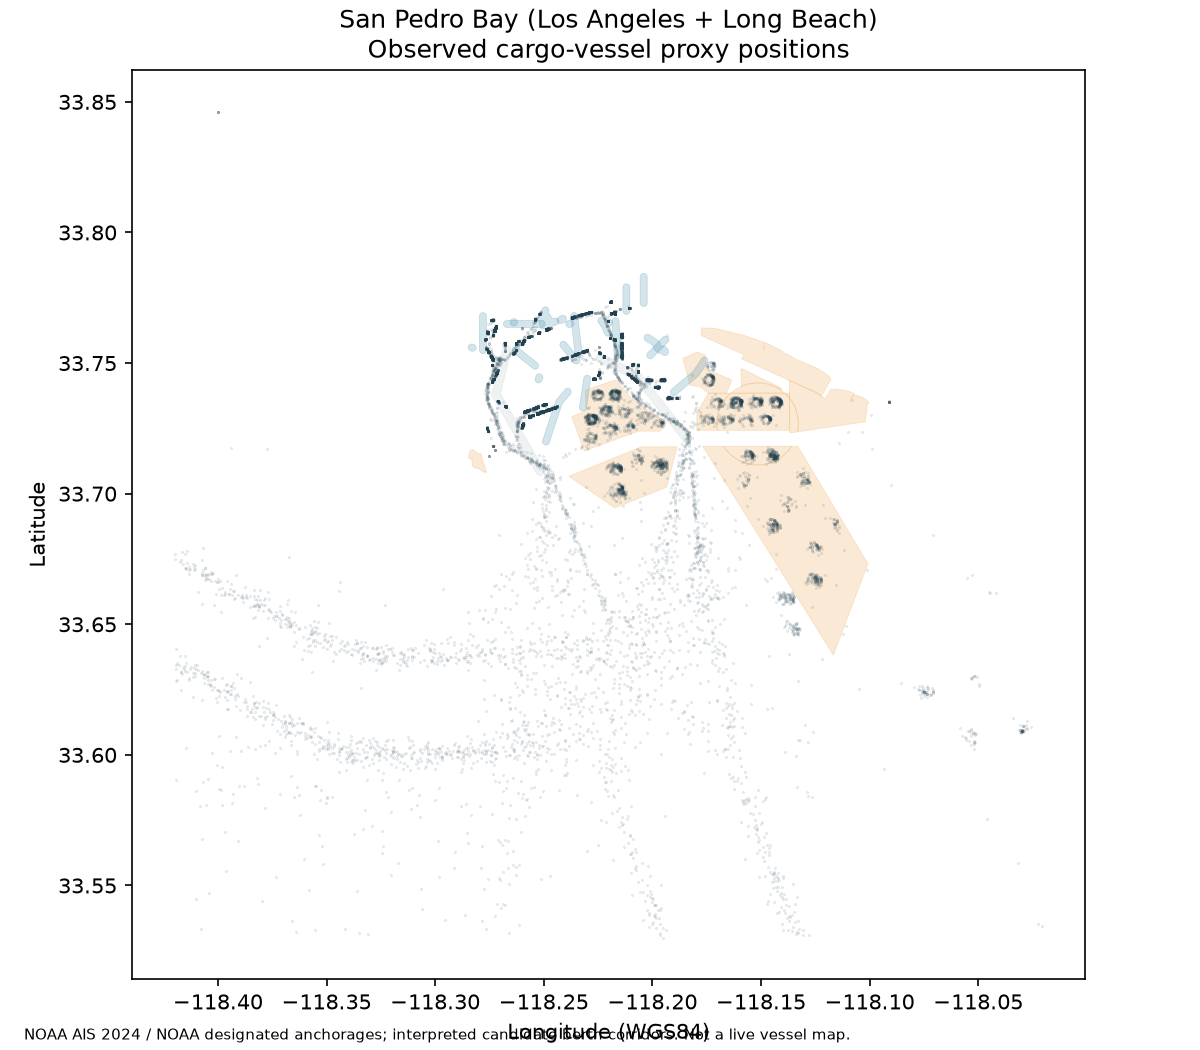

In [4]:
display(Image(filename=str(ROOT / "artifacts/audit/geo_map_san_pedro_bay.png"), width=850))


## Sensitivity and audit scope

These are prespecified measurement sensitivities, never used to retune H1 forecasting. The 60 retained agent-assisted trajectory reviews belong to the original 14-day pilot, not a new stratified full-year review. Agent-assisted trajectory review is not independent maritime-expert validation. A later berth arrival may support retrospective QA, but must not rewrite an earlier observable queue state.

In [5]:
sensitivity = pd.read_csv(ROOT / "artifacts/audit/geo_sensitivity.csv")
display(sensitivity[["scenario", "gateway_id", "source_days", "anchorage_hours", "berth_hours", "mean_queue_stock", "valid_queue_days"]])
audit = pd.read_csv(ROOT / "artifacts/audit/geo_trajectory_audit.csv")
display(audit.groupby(["gateway_id", "reviewer_type", "review_status"]).size().rename("examples").reset_index())
# Private identifiers remain in memory only and are not notebook outputs.
del clean, points, intervals, episodes


,scenario,gateway_id,source_days,anchorage_hours,berth_hours,mean_queue_stock,valid_queue_days
0,baseline,new_york_new_jersey,366,10461.999444,92847.270278,1.088068,352
1,baseline,san_pedro_bay,366,30825.891944,20853.348611,3.494286,350
2,baseline,savannah,366,0.000000,38894.487222,0.000000,357
3,buffer_100m,new_york_new_jersey,366,11882.054722,93058.723056,1.289773,352
4,buffer_100m,san_pedro_bay,366,30865.955278,54804.786944,3.497143,350
5,buffer_100m,savannah,366,0.000000,51414.193333,0.000000,357
6,buffer_250m,new_york_new_jersey,366,12922.626389,95157.041944,1.414773,352
7,buffer_250m,san_pedro_bay,366,30648.272500,93195.893333,3.522857,350
8,buffer_250m,savannah,366,0.000000,51860.773333,0.000000,357
9,speed_0.5kn,new_york_new_jersey,366,9949.324167,92453.778611,1.051136,352


,gateway_id,reviewer_type,review_status,examples
0,new_york_new_jersey,agent_assisted,agent_visual_reviewed_all60_contact_panels,20
1,san_pedro_bay,agent_assisted,agent_visual_reviewed_all60_contact_panels,20
2,savannah,agent_assisted,agent_visual_reviewed_all60_contact_panels,20
